# MESD Project

**Reference:** Zhang et al., *Descriptor: MOSFET Electrical Simulation Dataset (MESD)*, IEEE Data Descriptions, 2024.

## 1. Data Exploration

### Import Libraries

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
# Locate the MESD project directory
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name != "mesd-ml-project":
    PROJECT_DIR = PROJECT_DIR / "mesd-ml-project"

DATA_DIR = PROJECT_DIR / "data" / "raw"

device_files = sorted(DATA_DIR.glob("N55A-nmos*.json"))

print("Dataset directory:", DATA_DIR.resolve())
print("Found files:", [p.name for p in device_files])

assert len(device_files) == 3, (
    f"Expected 3 N55A NMOS files; found {len(device_files)}"
)

devices = {}

for path in device_files:
    with open(path, "r") as f:
        devices[path.stem] = json.load(f)

print("Loaded devices:", list(devices))

Dataset directory: /home/sanjinomo/course_work/cpe_586_ml/mesd-ml-project/data/raw
Found files: ['N55A-nmos1.json', 'N55A-nmos2.json', 'N55A-nmos3.json']
Loaded devices: ['N55A-nmos1', 'N55A-nmos2', 'N55A-nmos3']


### Inspect device metadata and JSON structure

In [10]:
#Compare metadata and record structure of all three devices

for name, data in devices.items():
    print(f"\n{'=' * 55}")
    print(f"DEVICE: {name}")
    print(f"{'=' * 55}")

    #Display device metadata
    for key, value in data.items():
        if key not in ("Records", "Record"):
            print(f"{key}: {value}")

    #Inspect simulation records
    records = data.get("Records", data.get("Record", []))

    print(f"Number of simulation records: {len(records):,}")

    if records:
        print("Fields in first record:", list(records[0].keys()))

        first_record = {
            key: (
                f"Array of {len(value)} values"
                if isinstance(value, list)
                else value
            )
            for key, value in records[0].items()
        }

        display(pd.DataFrame([first_record]))


DEVICE: N55A-nmos1
PDK: N55A
Node: 55
Model: BSIM4.5
Device: nmos1
Type: NMOS
Simulator: spectre
Number of simulation records: 7,500
Fields in first record: ['W', 'L', 'Corner', 'Temp', 'Vds', 'Vgs', 'Ids', 'Cgg', 'Cgs', 'Cgd', 'Cgb']


,W,L,Corner,Temp,Vds,Vgs,Ids,Cgg,Cgs,Cgd,Cgb
0,120,60,tt,-40,0.0,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values



DEVICE: N55A-nmos2
PDK: N55A
Node: 55
Model: BSIM4.5
Device: nmos2
Type: NMOS
Simulator: spectre
Number of simulation records: 7,500
Fields in first record: ['W', 'L', 'Corner', 'Temp', 'Vds', 'Vgs', 'Ids', 'Cgg', 'Cgs', 'Cgd', 'Cgb']


,W,L,Corner,Temp,Vds,Vgs,Ids,Cgg,Cgs,Cgd,Cgb
0,120,60,tt,-40,0.0,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values



DEVICE: N55A-nmos3
PDK: N55A
Node: 55
Model: BSIM4.5
Device: nmos3
Type: NMOS
Simulator: spectre
Number of simulation records: 7,500
Fields in first record: ['W', 'L', 'Corner', 'Temp', 'Vds', 'Vgs', 'Ids', 'Cgg', 'Cgs', 'Cgd', 'Cgb']


,W,L,Corner,Temp,Vds,Vgs,Ids,Cgg,Cgs,Cgd,Cgb
0,120,60,tt,-40,0.0,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values,Array of 13 values


## Create DataFrames

In [11]:
#Convert JSON voltage sweeps into individual operating points

def flatten_device(data):
    rows = []

    records = data["Records"]

    for sweep_id, record in enumerate(records):

        vgs_values = record["Vgs"]
        ids_values = record["Ids"]

        assert len(vgs_values) == len(ids_values), (
            f"Vgs/Ids length mismatch in sweep {sweep_id}"
        )

        for vgs, ids in zip(vgs_values, ids_values):
            rows.append({
                "sweep_id": sweep_id,
                "W": record["W"],
                "L": record["L"],
                "Corner": record["Corner"],
                "Temp": record["Temp"],
                "Vds": record["Vds"],
                "Vgs": vgs,
                "Ids": ids
            })

    return pd.DataFrame(rows)


device_dfs = {
    name: flatten_device(data)
    for name, data in devices.items()
}

for name, df_device in device_dfs.items():
    print(f"{name}: {len(df_device):,} operating points")

display(device_dfs["N55A-nmos1"].head())

N55A-nmos1: 97,500 operating points
N55A-nmos2: 97,500 operating points
N55A-nmos3: 97,500 operating points


,sweep_id,W,L,Corner,Temp,Vds,Vgs,Ids
0,0,120,60,tt,-40,0.0,0.0,-0.000000e+00
1,0,120,60,tt,-40,0.0,0.1,-9.893700e-15
2,0,120,60,tt,-40,0.0,0.2,-3.573000e-14
3,0,120,60,tt,-40,0.0,0.3,-7.289600e-14
4,0,120,60,tt,-40,0.0,0.4,-1.187000e-13


### Compare operating conditions

In [12]:
#compare operating conditions across all three devices

summary = []

for name, df_device in device_dfs.items():
    summary.append({
        "Device": name,
        "Operating points": len(df_device),
        "Widths": df_device["W"].nunique(),
        "Lengths": df_device["L"].nunique(),
        "Temperatures": df_device["Temp"].nunique(),
        "Corners": df_device["Corner"].nunique(),
        "Vds values": df_device["Vds"].nunique(),
        "Vgs values": df_device["Vgs"].nunique(),
        "Min Ids (A)": df_device["Ids"].min(),
        "Max Ids (A)": df_device["Ids"].max()
    })

device_summary = pd.DataFrame(summary)

display(device_summary)

,Device,Operating points,Widths,Lengths,Temperatures,Corners,Vds values,Vgs values,Min Ids (A),Max Ids (A)
0,N55A-nmos1,97500,10,10,5,3,5,13,-0.000003,0.069687
1,N55A-nmos2,97500,10,10,5,3,5,13,-0.000002,0.049586
2,N55A-nmos3,97500,10,10,5,3,5,13,-0.000003,0.080148


### Data Quality and Operating Conditions

In [13]:
#Data quality comparison done by checking for missing values, non-finite Ids, zero Ids, negative Ids, and duplicate input points
quality_results = []

for name, df_device in device_dfs.items():

    quality_results.append({
        "Device": name,
        "Missing values": int(df_device.isna().sum().sum()),
        "Non-finite Ids": int(
            (~np.isfinite(df_device["Ids"])).sum()
        ),
        "Zero Ids": int((df_device["Ids"] == 0).sum()),
        "Negative Ids": int((df_device["Ids"] < 0).sum()),
        "Negative Ids (Vds=0)": int(
            ((df_device["Ids"] < 0) &
             (df_device["Vds"] == 0)).sum()
        ),
        "Negative Ids (Vds>0)": int(
            ((df_device["Ids"] < 0) &
             (df_device["Vds"] > 0)).sum()
        ),
        "Duplicate input points": int(
            df_device.duplicated(
                subset=["W", "L", "Corner", "Temp", "Vds", "Vgs"]
            ).sum()
        )
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)


,Device,Missing values,Non-finite Ids,Zero Ids,Negative Ids,Negative Ids (Vds=0),Negative Ids (Vds>0),Duplicate input points
0,N55A-nmos1,0,0,1500,18000,18000,0,0
1,N55A-nmos2,0,0,1500,18000,18000,0,0
2,N55A-nmos3,0,0,1500,18000,18000,0,0


### Compare actual MOSFET I–V characteristics

#### Plot: Ids vs Vgs for all three devices

N55A-nmos1: 13 points
N55A-nmos2: 13 points
N55A-nmos3: 13 points


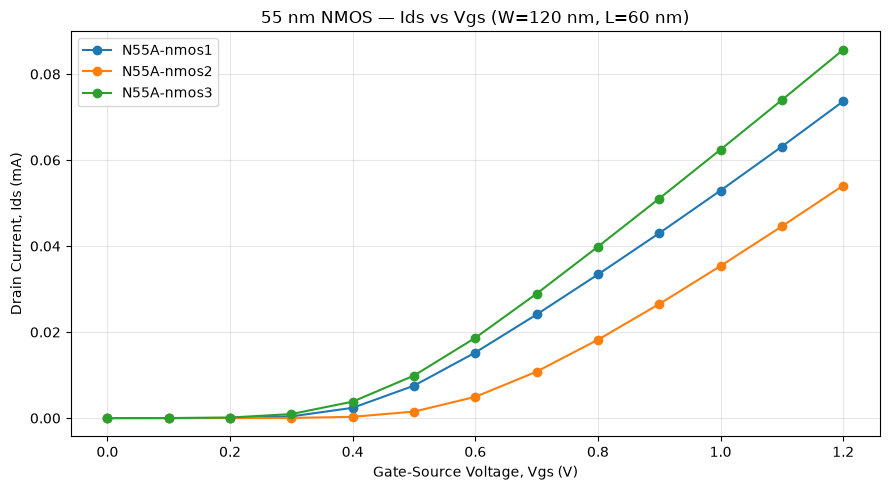

In [16]:
#compare Ids vs Vgs for all three devices
plt.figure(figsize=(9, 5))

for name, df_device in device_dfs.items():

    subset = df_device[
        (df_device["W"] == 120) &
        (df_device["L"] == 60) &
        (df_device["Temp"] == 25) &
        (df_device["Corner"] == "tt") &
        (np.isclose(df_device["Vds"], 1.2))
    ].sort_values("Vgs")

    print(f"{name}: {len(subset)} points")

    plt.plot(
        subset["Vgs"],
        subset["Ids"] * 1e3,
        marker="o",
        label=name
    )

plt.xlabel("Gate-Source Voltage, Vgs (V)")
plt.ylabel("Drain Current, Ids (mA)")
plt.title("55 nm NMOS — Ids vs Vgs (W=120 nm, L=60 nm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Plot: Ids vs Vds

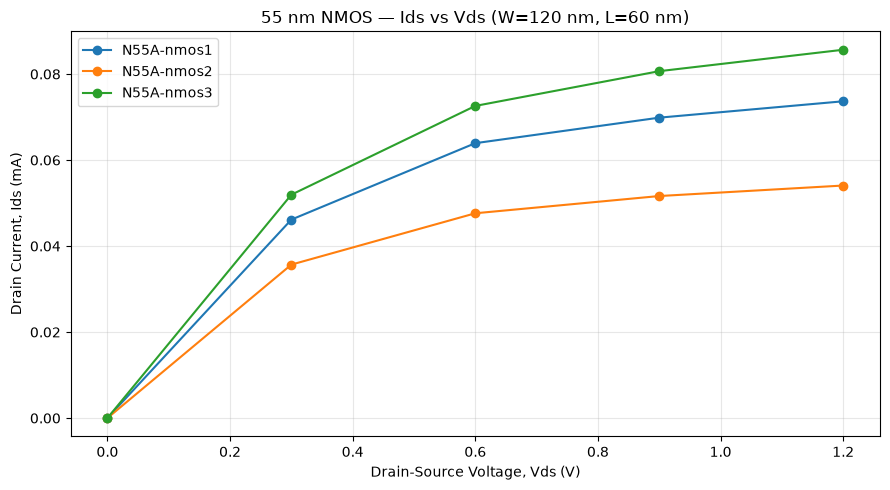

In [17]:
#compare Ids vs Vgs for all three devices
plt.figure(figsize=(9, 5))

for name, df_device in device_dfs.items():

    subset = df_device[
        (df_device["W"] == 120) &
        (df_device["L"] == 60) &
        (df_device["Temp"] == 25) &
        (df_device["Corner"] == "tt") &
        (np.isclose(df_device["Vgs"], 1.2))
    ].sort_values("Vds")

    plt.plot(
        subset["Vds"],
        subset["Ids"] * 1e3,
        marker="o",
        label=name
    )

plt.xlabel("Drain-Source Voltage, Vds (V)")
plt.ylabel("Drain Current, Ids (mA)")
plt.title("55 nm NMOS — Ids vs Vds (W=120 nm, L=60 nm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 2. Preprocessing — Paper Reproduction

The original MESD study uses six operating condition and device geometry features to analyze their importance for drain current. We retain the complete dataset initially and prepare the categorical process corner feature for tree based analysis.

In [18]:
#Prepare first 55 nm NMOS device for reproduction

df_repro = device_dfs["N55A-nmos1"].copy()

features = ["Corner", "Temp", "W", "L", "Vds", "Vgs"]
target = "Ids"

X_repro = pd.get_dummies(
    df_repro[features],
    columns=["Corner"],
    dtype=int
)

y_repro = df_repro[target]

print("Observations:", len(df_repro))
print("Input features:", X_repro.columns.tolist())
print("Target:", target)

assert X_repro.notna().all().all()
assert np.isfinite(y_repro).all()

display(X_repro.head())

Observations: 97500
Input features: ['Temp', 'W', 'L', 'Vds', 'Vgs', 'Corner_ff', 'Corner_ss', 'Corner_tt']
Target: Ids


,Temp,W,L,Vds,Vgs,Corner_ff,Corner_ss,Corner_tt
0,-40,120,60,0.0,0.0,0,0,1
1,-40,120,60,0.0,0.1,0,0,1
2,-40,120,60,0.0,0.2,0,0,1
3,-40,120,60,0.0,0.3,0,0,1
4,-40,120,60,0.0,0.4,0,0,1


In [19]:

from sklearn.tree import DecisionTreeRegressor

importance_model = DecisionTreeRegressor(
    max_depth=12,
    min_samples_leaf=5,
    random_state=42
)

importance_model.fit(X_repro, y_repro)

# Aggregate one-hot encoded process corners
raw_importance = pd.Series(
    importance_model.feature_importances_,
    index=X_repro.columns
)

importance = pd.Series({
    "Corner": raw_importance.filter(like="Corner_").sum(),
    "Temp": raw_importance["Temp"],
    "W": raw_importance["W"],
    "L": raw_importance["L"],
    "Vds": raw_importance["Vds"],
    "Vgs": raw_importance["Vgs"]
})

display(importance.sort_values(ascending=False).round(4))


Vgs       0.3718
L         0.2493
Vds       0.1762
W         0.1690
Corner    0.0275
Temp      0.0061
dtype: float64

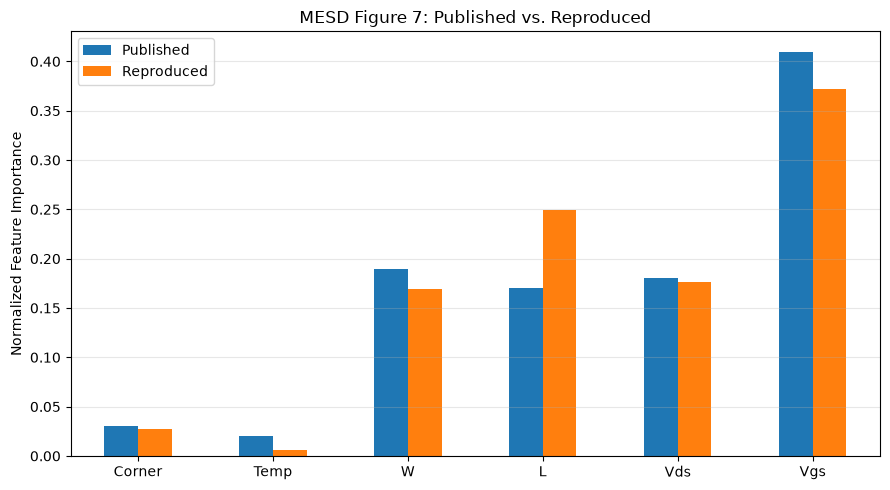

,Published,Reproduced
Corner,0.03,0.0275
Temp,0.02,0.0061
W,0.19,0.1690
L,0.17,0.2493
Vds,0.18,0.1762
Vgs,0.41,0.3718


In [20]:

paper_importance = pd.Series({
    "Corner": 0.03,
    "Temp": 0.02,
    "W": 0.19,
    "L": 0.17,
    "Vds": 0.18,
    "Vgs": 0.41
})

comparison = pd.DataFrame({
    "Published": paper_importance,
    "Reproduced": importance
})

ax = comparison.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_ylabel("Normalized Feature Importance")
ax.set_title("MESD Figure 7: Published vs. Reproduced")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(comparison.round(4))


In [21]:
#Feature importance comparison across three 55 nm NMOS devices

from sklearn.tree import DecisionTreeRegressor

feature_order = ["Corner", "Temp", "W", "L", "Vds", "Vgs"]

device_importances = {}

for name, df_device in device_dfs.items():

    X_device = pd.get_dummies(
        df_device[feature_order],
        columns=["Corner"],
        dtype=int
    )

    y_device = df_device["Ids"]

    model = DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42
    )

    model.fit(X_device, y_device)

    raw = pd.Series(
        model.feature_importances_,
        index=X_device.columns
    )

    device_importances[name] = {
        "Corner": raw.filter(like="Corner_").sum(),
        "Temp": raw["Temp"],
        "W": raw["W"],
        "L": raw["L"],
        "Vds": raw["Vds"],
        "Vgs": raw["Vgs"]
    }

importance_comparison = pd.DataFrame(device_importances)
importance_comparison.insert(
    0, "Published", paper_importance
)

display(importance_comparison.round(4))


,Published,N55A-nmos1,N55A-nmos2,N55A-nmos3
Corner,0.03,0.0275,0.0277,0.0219
Temp,0.02,0.0061,0.0013,0.0089
W,0.19,0.1690,0.1528,0.1870
L,0.17,0.2493,0.2526,0.2453
Vds,0.18,0.1762,0.1760,0.1808
Vgs,0.41,0.3718,0.3896,0.3560


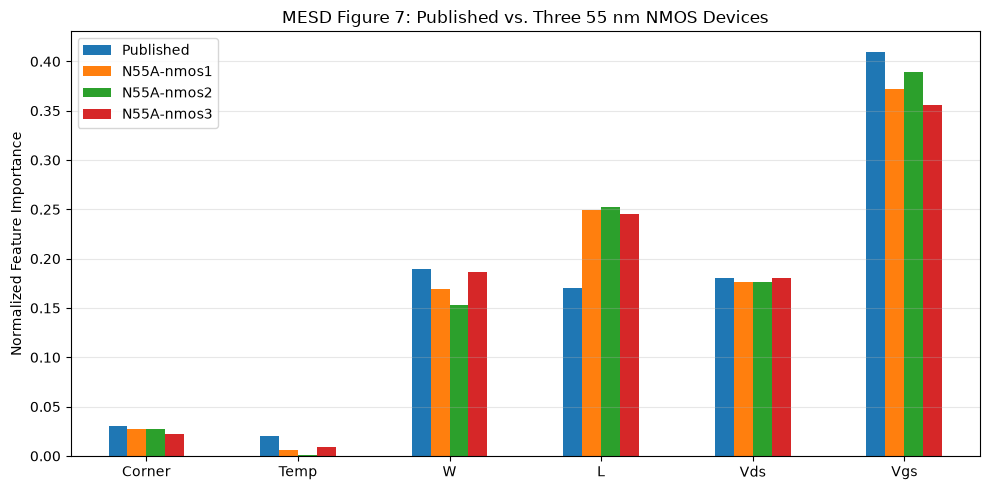

In [22]:
#plot for feature importance comparison across three 55 nm NMOS devices
importance_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.ylabel("Normalized Feature Importance")
plt.title("MESD Figure 7: Published vs. Three 55 nm NMOS Devices")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
